# Prevenção de Evasão Escolar no Ensino Médio Técnico
### Etapa 1 — Exploração do dataset de prototipagem

**Disciplina:** Projetos Integrados II · **Professor:** Romualdo Mathias Filho

**Equipe:** Róbson de Oliveira Cabral · Sidnário Oliveira Rosa · Lucca Queiroz · Lissa Ferreira Massuda · Nathália Vieira Kamimura

Este notebook cobre a primeira etapa do cronograma do projeto: carregar o dataset público de prototipagem e fazer a análise exploratória inicial (EDA), antes de partir para a limpeza, engenharia de atributos e treino dos modelos (próxima etapa).

**Dataset:** [Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) (UCI Machine Learning Repository). É uma base de ensino superior português — usada aqui só para validar o pipeline; o modelo será retreinado com dados reais da escola assim que disponíveis (ver o documento de Arquitetura e Plano Técnico do grupo).


## 1. Instalação e imports

No Google Colab, a primeira célula abaixo instala a biblioteca `ucimlrepo`, que baixa o dataset direto do repositório oficial da UCI.

In [1]:
# Só é necessário rodar esta linha uma vez por sessão do Colab
%pip install -q ucimlrepo


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 2. Carregando o dataset

O `fetch_ucirepo` baixa as features e o alvo (`Target`) diretamente da UCI e já separa X e y.

In [3]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=697)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)
print(f"Formato do dataset: {df.shape[0]} alunos, {df.shape[1]} colunas")
df.head()


Formato do dataset: 4424 alunos, 37 colunas


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 3. Visão geral e qualidade dos dados

Antes de qualquer análise, conferimos tipos de dados e valores ausentes.

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [5]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]
print(f"Colunas com valores ausentes: {len(nulos)}")
nulos


Colunas com valores ausentes: 0


Series([], dtype: int64)

Não há valores ausentes nesta base — o que é comum em datasets já curados para benchmark. Na base real da escola, essa etapa de limpeza deve exigir mais atenção (faltas não registradas, notas em branco etc.).

## 4. Distribuição do desfecho original

O dataset traz três categorias de desfecho do aluno: `Dropout`, `Enrolled` e `Graduate`.

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


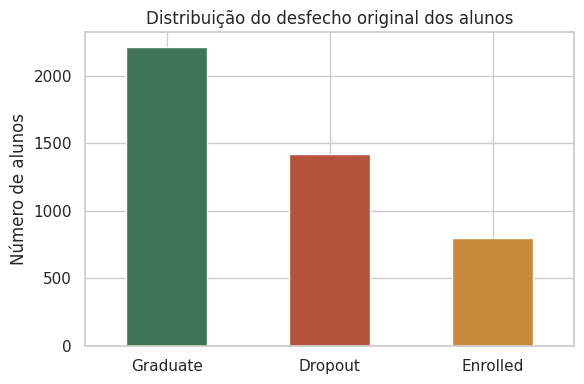

In [6]:
contagem_target = df["Target"].value_counts()
print(contagem_target)

plt.figure(figsize=(6, 4))
cores = {"Dropout": "#B5533C", "Enrolled": "#C98A3D", "Graduate": "#3F7554"}
contagem_target.plot(kind="bar", color=[cores[c] for c in contagem_target.index])
plt.title("Distribuição do desfecho original dos alunos")
plt.ylabel("Número de alunos")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Reagrupando em níveis de risco

Como já definido com o grupo, o desfecho original é reagrupado nos três níveis de risco usados no projeto — **sem usar os rótulos originais em inglês** no restante da análise:

- `Dropout` → **Risco Alto**
- `Enrolled` → **Risco Médio**
- `Graduate` → **Risco Baixo**


risco
Risco Alto     1421
Risco Médio     794
Risco Baixo    2209
Name: count, dtype: int64

Proporção:
risco
Risco Alto     32.1
Risco Médio    17.9
Risco Baixo    49.9
Name: count, dtype: float64


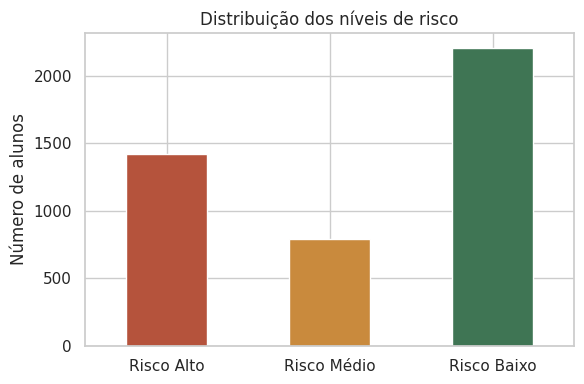

In [7]:
mapa_risco = {
    "Dropout": "Risco Alto",
    "Enrolled": "Risco Médio",
    "Graduate": "Risco Baixo",
}
df["risco"] = df["Target"].map(mapa_risco)

ordem_risco = ["Risco Alto", "Risco Médio", "Risco Baixo"]
cores_risco = {"Risco Alto": "#B5533C", "Risco Médio": "#C98A3D", "Risco Baixo": "#3F7554"}

contagem_risco = df["risco"].value_counts().reindex(ordem_risco)
print(contagem_risco)
print(f"\nProporção:\n{(contagem_risco / len(df) * 100).round(1)}")

plt.figure(figsize=(6, 4))
contagem_risco.plot(kind="bar", color=[cores_risco[c] for c in ordem_risco])
plt.title("Distribuição dos níveis de risco")
plt.ylabel("Número de alunos")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


As classes estão desbalanceadas (bem mais alunos em Risco Baixo do que em Risco Alto ou Médio) — isso já está mapeado como risco no documento de Riscos e Mitigações do grupo, e vai pesar na escolha das métricas de avaliação do modelo (recall por classe, não só acurácia).

## 6. Fatores acadêmicos — proxy de desempenho e frequência

O dataset não tem uma coluna literal de frequência (absenteísmo). Como proxy, usamos as colunas `Curricular units` de cada semestre — em especial a proporção de unidades curriculares aprovadas em relação às matriculadas, que reflete engajamento e desempenho.

In [8]:
df["taxa_aprovacao_1sem"] = (
    df["Curricular units 1st sem (approved)"] / df["Curricular units 1st sem (enrolled)"].replace(0, np.nan)
)
df["taxa_aprovacao_2sem"] = (
    df["Curricular units 2nd sem (approved)"] / df["Curricular units 2nd sem (enrolled)"].replace(0, np.nan)
)

resumo_academico = df.groupby("risco")[[
    "taxa_aprovacao_1sem", "taxa_aprovacao_2sem",
    "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
]].mean().reindex(ordem_risco).round(2)
resumo_academico


,taxa_aprovacao_1sem,taxa_aprovacao_2sem,Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
risco,,,,
Risco Alto,0.41,0.31,7.26,5.90
Risco Médio,0.71,0.67,11.13,11.12
Risco Baixo,0.93,0.93,12.64,12.70


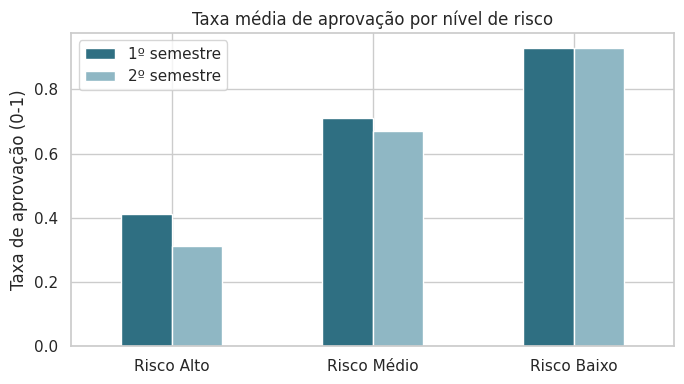

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
resumo_academico[["taxa_aprovacao_1sem", "taxa_aprovacao_2sem"]].plot(
    kind="bar", ax=ax, color=["#2F6F82", "#8FB7C4"]
)
ax.set_title("Taxa média de aprovação por nível de risco")
ax.set_ylabel("Taxa de aprovação (0-1)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(["1º semestre", "2º semestre"])
plt.tight_layout()
plt.show()


A taxa de aprovação cai claramente do Risco Baixo para o Risco Alto, como esperado — é um bom sinal de que esse proxy de desempenho/frequência tem poder preditivo real, mesmo sem uma coluna direta de faltas.

## 7. Fatores socioeconômicos

Como proxy de classe econômica, olhamos para `Scholarship holder` (bolsista), `Debtor` (inadimplente) e `Tuition fees up to date` (mensalidades em dia).

In [10]:
fatores_socioeconomicos = ["Scholarship holder", "Debtor", "Tuition fees up to date"]

resumo_socioeconomico = df.groupby("risco")[fatores_socioeconomicos].mean().reindex(ordem_risco).round(2)
resumo_socioeconomico.columns = ["% bolsistas", "% inadimplentes", "% mensalidades em dia"]
(resumo_socioeconomico * 100).round(1)


,% bolsistas,% inadimplentes,% mensalidades em dia
risco,,,
Risco Alto,9.0,22.0,68.0
Risco Médio,16.0,11.0,95.0
Risco Baixo,38.0,5.0,99.0


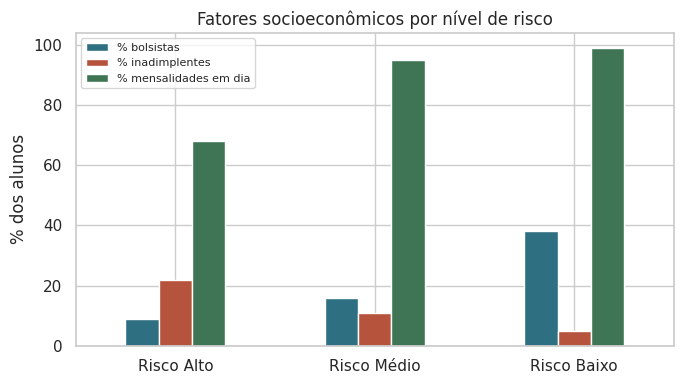

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
(resumo_socioeconomico * 100).plot(kind="bar", ax=ax, color=["#2F6F82", "#B5533C", "#3F7554"])
ax.set_title("Fatores socioeconômicos por nível de risco")
ax.set_ylabel("% dos alunos")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


Alunos em Risco Alto têm taxa de inadimplência bem maior e proporção menor de mensalidades em dia — confirma que o indicador socioeconômico combinado (já planejado no documento de arquitetura) faz sentido como atributo do modelo.

## 8. Próximos passos

Esta etapa cobriu o carregamento e a exploração inicial do dataset de prototipagem. Os próximos passos do pipeline (ver Cronograma do Projeto) são:

1. Limpeza final e engenharia de atributos (consolidar o indicador socioeconômico, normalizar notas).
2. Split treino/teste estratificado.
3. Treino da Regressão Logística e da Árvore de Decisão.
4. Avaliação por classe de risco (foco em recall da classe Risco Alto).
5. Exportação do modelo treinado para o dashboard Streamlit.

O dataset consolidado desta etapa é salvo em `dados/processado/dataset_explorado.csv` para servir de ponto de partida do próximo notebook.

In [12]:
import os

os.makedirs("../dados/processado", exist_ok=True)
df.to_csv("../dados/processado/dataset_explorado.csv", index=False)
print("Arquivo salvo em dados/processado/dataset_explorado.csv")
print(f"{df.shape[0]} linhas, {df.shape[1]} colunas")


Arquivo salvo em dados/processado/dataset_explorado.csv
4424 linhas, 40 colunas
